In [1]:
!pip install tensorflow --upgrade

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.9/572.9 MB 58.9 MB/s  0:00:06
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 107.7 MB/s  0:00:00
  Attempting uninstall: protobuf
    Found existing installation: protobuf 5.29.5
    Uninstalling protobuf-5.29.5:
      Successfully uninstalled protobuf-5.29.5
  Attempting uninstall: h5py
    Found existing installation: h5py 3.16.0
    Uninstalling h5py-3.16.0:
      Successfully uninstalled h5py-3.16.0
  Attempting uninstall: tensorflow
    Found existing installation: tensorflow 2.20.0
    Uninstalling tensorflow-2.20.0:
      Successfully uninstalled tensorflow-2.20.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [tensorflow]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
grpcio-tools 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 7.36.2 which is incompatible.
dopamine-rl 4.1.2 requi

In [2]:
import tensorflow as tf
tf.__version__

'2.21.0'

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix

In [4]:
BASE = "/kaggle/input/datasets/oualidlaib/"

In [5]:
PATH = os.path.join(BASE,"skin-lesions/Dataset")
PATH

'/kaggle/input/datasets/oualidlaib/skin-lesions/Dataset'

In [6]:
BATCH_SIZE = 128
IMG_SIZE = (299, 299)

train_dir = os.path.join(PATH,'train')
train_dataset = tf.keras.utils.image_dataset_from_directory(train_dir,
                                                            shuffle=True,
                                                            batch_size=BATCH_SIZE,
                                                            image_size=IMG_SIZE
                                                            )

validation_dir = os.path.join(PATH,'validation')
validation_dataset = tf.keras.utils.image_dataset_from_directory(validation_dir,
                                                            batch_size=BATCH_SIZE,
                                                            image_size=IMG_SIZE,
                                                            shuffle=False)


test_dir = os.path.join(PATH,'test')
test_dataset = tf.keras.utils.image_dataset_from_directory(test_dir,
                                                            batch_size=BATCH_SIZE,
                                                            image_size=IMG_SIZE,
                                                            shuffle=False)


Found 8493 files belonging to 2 classes.
Found 1060 files belonging to 2 classes.
Found 1061 files belonging to 2 classes.


In [7]:
class_names = train_dataset.class_names
class_names

['benign', 'malignant']

In [8]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.prefetch(buffer_size=AUTOTUNE)

In [9]:
IMG_SHAPE = IMG_SIZE + (3,)
base_model = tf.keras.applications.ResNet101V2(
    include_top=False,
    weights="imagenet",
    input_shape=IMG_SHAPE
)

171317808/171317808 ━━━━━━━━━━━━━━━━━━━━ 9s 0us/step


In [10]:
base_model.trainable = False

In [11]:
base_model.summary()

Model: "resnet101v2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 299, 299,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 305, 305,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 150, 150,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 152, 152,  │          0 │ conv1_conv[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 75, 75,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_preac… │ (None, 75, 75,    │        256 │ pool1_pool[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_preac… │ (None, 75, 75,    │          0 │ conv2_block1_pre… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 75, 75,    │      4,096 │ conv2_block1_pre… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 75, 75,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 75, 75,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_pad  │ (None, 77, 77,    │          0 │ conv2_block1_1_r… │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 75, 75,    │     36,864 │ conv2_block1_2_p… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 75, 75,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 75, 75,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 75, 75,    │     16,640 │ conv2_block1_pre… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 75, 75,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_out    │ (None, 75, 75,    │          0 │ conv2_block1_0_c

 Total params: 42,626,560 (162.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 42,626,560 (162.61 MB)

In [12]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomBrightness(factor=0.1),
    tf.keras.layers.RandomZoom(height_factor=(-0.1, 0.1), width_factor=(-0.1, 0.1))
], name="data_augmentation")

In [13]:
inputs = tf.keras.Input(shape=IMG_SHAPE)

x = data_augmentation(inputs)
x = tf.keras.applications.resnet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dense(254, activation='swish', kernel_initializer=tf.keras.initializers.GlorotUniform(seed=41))(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = tf.keras.layers.Dense(2, activation='softmax', kernel_initializer=tf.keras.initializers.GlorotUniform(seed=41))(x)

model = tf.keras.Model(inputs, outputs)

In [14]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet101v2 (Functional)        │ (None, 10, 10, 2048)   │    42,626,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 254)            │       520,446 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 254)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           510 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 43,147,516 (164.59 MB)

 Trainable params: 520,956 (1.99 MB)

 Non-trainable params: 42,626,560 (162.61 MB)

In [15]:
base_learning_rate = 0.001 
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=base_learning_rate
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(name='accuracy')
    ]
)

In [16]:
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.1,
    patience=3,
    min_delta = 0.000001)

In [17]:
initial_epochs = 15

In [18]:
history = model.fit(
    train_dataset,
    epochs=initial_epochs,
    validation_data=validation_dataset,
    callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True), reduce_lr]
)

Epoch 1/15
67/67 ━━━━━━━━━━━━━━━━━━━━ 145s 2s/step - accuracy: 0.8605 - loss: 0.3327 - val_accuracy: 0.9151 - val_loss: 0.2133 - learning_rate: 0.0010
Epoch 2/15
67/67 ━━━━━━━━━━━━━━━━━━━━ 102s 2s/step - accuracy: 0.9020 - loss: 0.2391 - val_accuracy: 0.9236 - val_loss: 0.2001 - learning_rate: 0.0010
Epoch 3/15
67/67 ━━━━━━━━━━━━━━━━━━━━ 102s 2s/step - accuracy: 0.9106 - loss: 0.2136 - val_accuracy: 0.9208 - val_loss: 0.1954 - learning_rate: 0.0010
Epoch 4/15
67/67 ━━━━━━━━━━━━━━━━━━━━ 101s 2s/step - accuracy: 0.9201 - loss: 0.2030 - val_accuracy: 0.9255 - val_loss: 0.1808 - learning_rate: 0.0010
Epoch 5/15
67/67 ━━━━━━━━━━━━━━━━━━━━ 101s 2s/step - accuracy: 0.9185 - loss: 0.1974 - val_accuracy: 0.9330 - val_loss: 0.1840 - learning_rate: 0.0010
Epoch 6/15
67/67 ━━━━━━━━━━━━━━━━━━━━ 101s 2s/step - accuracy: 0.9275 - loss: 0.1828 - val_accuracy: 0.9255 - val_loss: 0.1827 - learning_rate: 0.0010
Epoch 7/15
67/67 ━━━━━━━━━━━━━━━━━━━━ 102s 2s/step - accuracy: 0.9278 - loss: 0.1812 - val_acc

In [19]:
loss0, accuracy0 = model.evaluate(test_dataset)

9/9 ━━━━━━━━━━━━━━━━━━━━ 18s 2s/step - accuracy: 0.9189 - loss: 0.2070


In [20]:
print("Loss before fine-tuning: {:.2f}".format(loss0))
print("Accuracy before fine-tuning: {:.2f}".format(accuracy0))

Loss before fine-tuning: 0.21
Accuracy before fine-tuning: 0.92


In [21]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

In [22]:
# Fine-tune from this layer onwards
fine_tune_at = 160

base_model.trainable = True
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False
    
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

In [23]:
# number of layers in the base model
print("Number of layers in the base model: ", len(base_model.layers))

Number of layers in the base model:  377


In [24]:
model.compile(
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=base_learning_rate / 1000
    ),
    metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name='accuracy')]
)

In [25]:
fine_tune_epochs = 15
total_epochs =  initial_epochs + fine_tune_epochs

history_fine = model.fit(train_dataset,
                         epochs=total_epochs,
                         initial_epoch=len(history.epoch),
                         validation_data=validation_dataset,
                         callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True), reduce_lr])

Epoch 16/30
67/67 ━━━━━━━━━━━━━━━━━━━━ 206s 3s/step - accuracy: 0.9476 - loss: 0.1356 - val_accuracy: 0.9340 - val_loss: 0.1634 - learning_rate: 1.0000e-06
Epoch 17/30
67/67 ━━━━━━━━━━━━━━━━━━━━ 176s 3s/step - accuracy: 0.9529 - loss: 0.1254 - val_accuracy: 0.9321 - val_loss: 0.1637 - learning_rate: 1.0000e-06
Epoch 18/30
67/67 ━━━━━━━━━━━━━━━━━━━━ 176s 3s/step - accuracy: 0.9542 - loss: 0.1207 - val_accuracy: 0.9340 - val_loss: 0.1623 - learning_rate: 1.0000e-06
Epoch 19/30
67/67 ━━━━━━━━━━━━━━━━━━━━ 176s 3s/step - accuracy: 0.9529 - loss: 0.1175 - val_accuracy: 0.9311 - val_loss: 0.1638 - learning_rate: 1.0000e-06
Epoch 20/30
67/67 ━━━━━━━━━━━━━━━━━━━━ 176s 3s/step - accuracy: 0.9560 - loss: 0.1154 - val_accuracy: 0.9349 - val_loss: 0.1636 - learning_rate: 1.0000e-06
Epoch 21/30
67/67 ━━━━━━━━━━━━━━━━━━━━ 176s 3s/step - accuracy: 0.9563 - loss: 0.1109 - val_accuracy: 0.9368 - val_loss: 0.1642 - learning_rate: 1.0000e-06
Epoch 22/30
67/67 ━━━━━━━━━━━━━━━━━━━━ 176s 3s/step - accuracy: 

In [26]:
acc += history_fine.history['accuracy']
val_acc += history_fine.history['val_accuracy']

loss += history_fine.history['loss']
val_loss += history_fine.history['val_loss']

9/9 ━━━━━━━━━━━━━━━━━━━━ 17s 2s/step
Classification Report
              precision    recall  f1-score   support

      Benign       0.91      0.95      0.93       550
   Malignant       0.94      0.90      0.92       511

    accuracy                           0.93      1061
   macro avg       0.93      0.93      0.93      1061
weighted avg       0.93      0.93      0.93      1061

Confusion Matrix


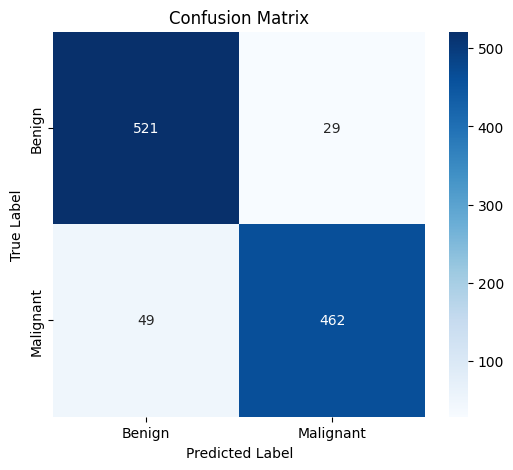

In [27]:
y_true = np.concatenate([y for x, y in test_dataset], axis=0)

Y_pred = model.predict(test_dataset)
y_pred = np.argmax(Y_pred, axis=1)


print('Classification Report')
target_names = ['Benign', 'Malignant']
print(classification_report(y_true, y_pred, target_names=target_names))


print('Confusion Matrix')
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=target_names, yticklabels=target_names) 
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

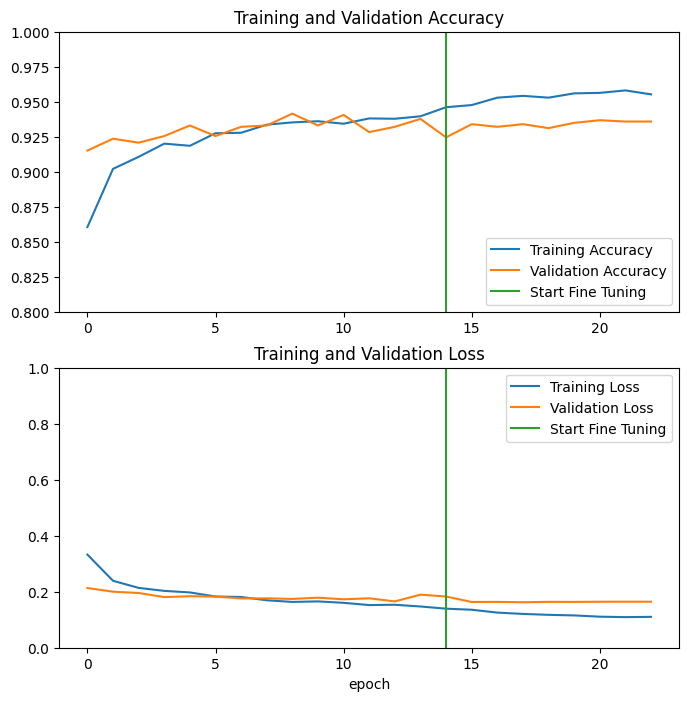

In [28]:
plt.figure(figsize=(8, 8))
plt.subplot(2, 1, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.ylim([0.8, 1])
plt.plot([initial_epochs-1,initial_epochs-1], 
         plt.ylim(), 
         label='Start Fine Tuning')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(2, 1, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.ylim([0, 1.0])
plt.plot([initial_epochs-1,initial_epochs-1],
         plt.ylim(), 
         label='Start Fine Tuning')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.xlabel('epoch')
plt.show()

In [29]:
model.save('skin-cancer-predictor.keras')